# Synthetic Data

Before the AEMC dataset becomes available, it will be useful to have a synthetic dataset to use for developing methods, setting up code, and preparing results.

Although the results themselves will not be representative, having a dataset with the same structure and variability should allow initial progress to be made. The structure is a timeseries for each state of solar energy generation, wind energy generation, and demand. The data is derived from solar, wind, and demand datasets currently available on Gadi, then tweaked a bit for this purpose.

In [12]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches
from pathlib import Path
import pandas

HOME_DIR = Path("/home/548/cd3022/repos/aus-energy-met")

# Supply

Supply data is based off ERA5 derived capacity factors. A small location from each state is selected, and then the spatial mean is taken to get a timeseries of capacity factors for each state. This makes the data roughly represent the real seasonal and diurnal variability of solar and wind.

In [2]:
# LOAD SOME SOLAR AND WIND DATA TO BASE SYNTHETIC DATA OFF
DATA_DIR = Path("/g/data/w42/dr6273/work/projects/Aus_energy/production_metrics")
SOLAR_DIR = DATA_DIR / "solar" / "capacity_factor" / "van_der_Wiel"
WIND_DIR = DATA_DIR / "wind" / "capacity_factor" / "van_der_Wiel"

SOLAR_FILES = sorted([f for f in SOLAR_DIR.glob("solar_capacity_factor_van_der_Wiel_era5_hourly*.nc")])
WIND_FILES = sorted([f for f in WIND_DIR.glob("wind_capacity_factor_van_der_Wiel_era5_hourly*.nc")])

solar = xr.open_mfdataset(SOLAR_FILES).sortby("lat")
wind = xr.open_mfdataset(WIND_FILES).sortby("lat")

In [3]:
# USE SMALL STATE REGIONS TO REPRESENT EACH STATE IN THE SYNTHETIC DATASET
state_coords = {
    "VIC": (-37.9, -36.5, 143.2, 145.8),
    "NSW": (-34.8, -33.5, 148.5, 150.7),
    "QLD": (-28.2, -26.8, 150.4, 152.8),
    "SA": (-35.0, -33.6, 138.5, 140.9),
}

Text(0.5, 1.0, 'Regions where data is taken from')

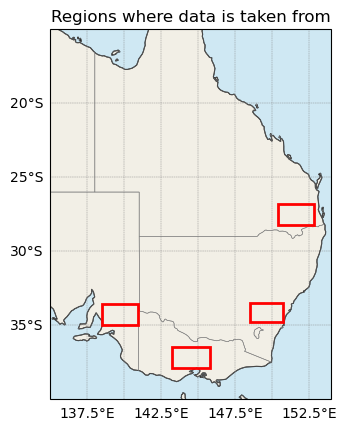

In [4]:
# SHOW THE REGIONS THAT HAVE BEEN SELECTED
def plot_bbox(
    bounds, # (lat_min, lat_max, lon_min, lon_max)
    ax,
):

    # Red bounding box
    lat_min, lat_max, lon_min, lon_max = bounds
    rect = mpatches.Rectangle(
        (lon_min, lat_min),
        lon_max - lon_min,
        lat_max - lat_min,
        linewidth=2,
        edgecolor="red",
        facecolor="none",
        transform=ccrs.PlateCarree(),
        zorder=10,
    )

    ax.add_patch(rect)

map_extent = [135, 154, -40, -15]
fig = plt.figure()#figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent(map_extent, crs=ccrs.PlateCarree())

# Base map features
ax.add_feature(cfeature.OCEAN, facecolor="#cfe8f3")
ax.add_feature(cfeature.LAND, facecolor="#f2efe6")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.STATES, linewidth=0.4, edgecolor="grey")
ax.add_feature(cfeature.BORDERS, linewidth=0.6)

# Gridlines with lat/lon labels
gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="grey", linestyle="--")
gl.top_labels = False
gl.right_labels = False

for state in state_coords:
    plot_bbox(state_coords[state], ax=ax)

plt.title("Regions where data is taken from")

In [5]:
# CALCULATE STATE CF TIMESERIES BY GETTING THE SPATIAL MEAN FROM WITHIN THESE REGIONS
state_solar = {}
state_wind = {}

for state in state_coords:
    state_solar[state] = solar.sel(
        lat=slice(state_coords[state][0], state_coords[state][1]),
        lon=slice(state_coords[state][2], state_coords[state][3]),
    ).mean(["lat", "lon"]).assign_coords({"state": state})

    state_wind[state] = wind.sel(
        lat=slice(state_coords[state][0], state_coords[state][1]),
        lon=slice(state_coords[state][2], state_coords[state][3]),
    ).mean(["lat", "lon"]).assign_coords({"state": state})

In [6]:
# COMBINE INTO ONE DATASET
solar_nem = xr.concat([ds for ds in state_solar.values()], dim="state")
wind_nem = xr.concat([ds for ds in state_wind.values()], dim="state")

wind_nem["wind_cf"] = wind_nem["capacity_factor"]
wind_nem = wind_nem["wind_cf"]
solar_nem["solar_cf"] = solar_nem["capacity_factor"]
solar_nem = solar_nem["solar_cf"]
nem = xr.merge([wind_nem, solar_nem])

/jobfs/184253768.gadi-pbs/ipykernel_358932/1920375384.py:9: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  nem = xr.merge([wind_nem, solar_nem])


# Demand

To produce a synthetic demand dataset, emulated daily demand data (https://21centuryweather.github.io/21st-Century-Weather-Software-Wiki/datasets/energy.html) is mixed with a "duck curve" function. The emulated dataset provides the daily magnitudes, and the duck curve function gives it roughly realistic diurnal variability.

In [7]:
# LOAD STATE BASED DEMAND CSV DATA AND ADD IT TO THE DATASET
arrays = []
for state in state_coords.keys():
    state_path = f"/g/data/su28/energy_demand/demand_{state}_daily_1940-2023.csv"
    df = pd.read_csv(state_path, comment="#", index_col="date", parse_dates=True)
    da = (
        df.iloc[:, 0]
        .rename("demand")
        .to_xarray()
        .rename(date="time")
        .reindex(time=nem.time, method="ffill", tolerance=pd.Timedelta(hours=23))
    )
    arrays.append(da.expand_dims(state=[state]))   # adds the state coordinate

demand = xr.concat(arrays, dim="state")
nem["demand"] = demand.reindex(state=nem.state).transpose("state", "time")

In [8]:
# DEFINE SINUSOIDAL FUNCTION FOR ADJUSTING DIURNAL DEMAND
def shape_demand(demand, weight=0.2, cycles_per_day=2, peak_hour=18):
    """
    demand * (1 + weight * wave), where wave is a sinusoid in time of day.

    weight         : amplitude as a fraction of demand (0.2 = +/-20 %)
    cycles_per_day : frequency (1 = one peak a day, 2 = two peaks a day)
    peak_hour      : hour of day at which the (first) peak occurs
    """
    hour = demand.time.dt.hour + demand.time.dt.minute / 60   # 0..24
    wave = np.cos(2 * np.pi * cycles_per_day * (hour - peak_hour) / 24)
    return demand * (1 + weight * wave)

# APPLY FUNCTION TO TWEAK THE SHAPE OF DEMAND
def duck_curve(demand):
    demand = shape_demand(demand, weight=0.1, cycles_per_day=2, peak_hour=18)
    demand = shape_demand(demand, weight=0.4, cycles_per_day=1, peak_hour=0)
    return demand

nem["demand"] = duck_curve(nem["demand"])

In [9]:
# SCALE UP SOLAR AND WIND CF TO GENERATION VALUES USING THE MEDIAN OF DEMAND
nem["solar_gen"] = nem["solar_cf"] * nem["demand"].median("time") * 0.5
nem["wind_gen"] = nem["wind_cf"] * nem["demand"].median("time") * 0.5

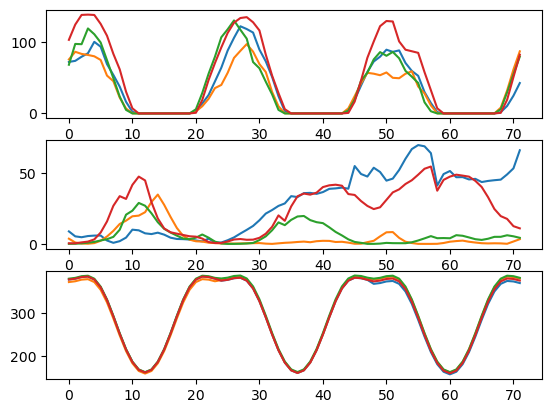

In [10]:
# PLOT EXAMPLE
fig, ax = plt.subplots(nrows=3, ncols=1)
for state in nem.state:
    ax[0].plot(nem.solar_gen.sel(state=state, time=slice("2021-01-02", "2021-01-04")))
    ax[1].plot(nem.wind_gen.sel(state=state, time=slice("2021-01-02", "2021-01-04")))
    ax[2].plot(nem.demand.sel(state=state, time=slice("2021-01-02", "2021-01-04")))

In [15]:
# save dataset to be used for preliminary analysis
nem.to_netcdf(HOME_DIR / "data/temp/synthetic_data.nc")